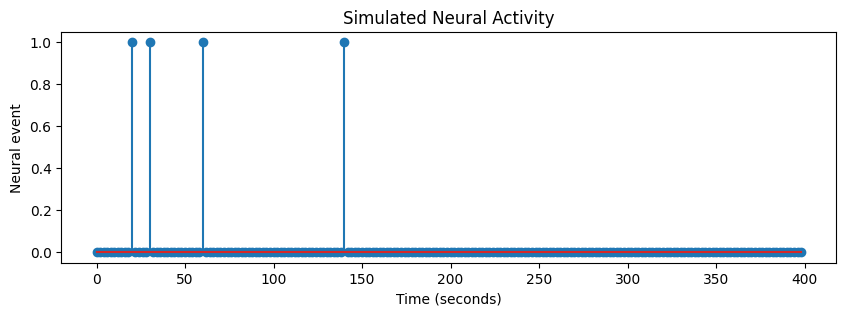

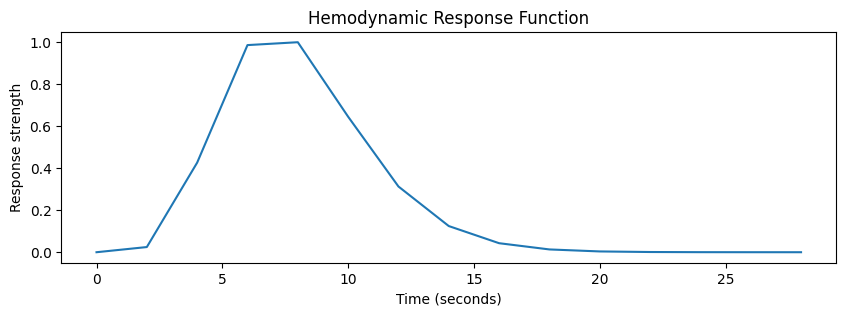

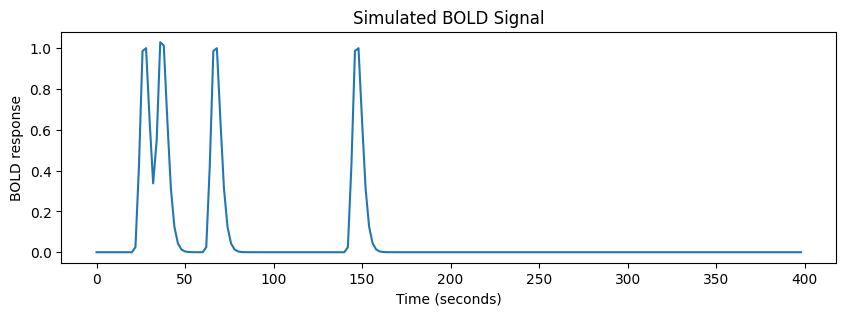

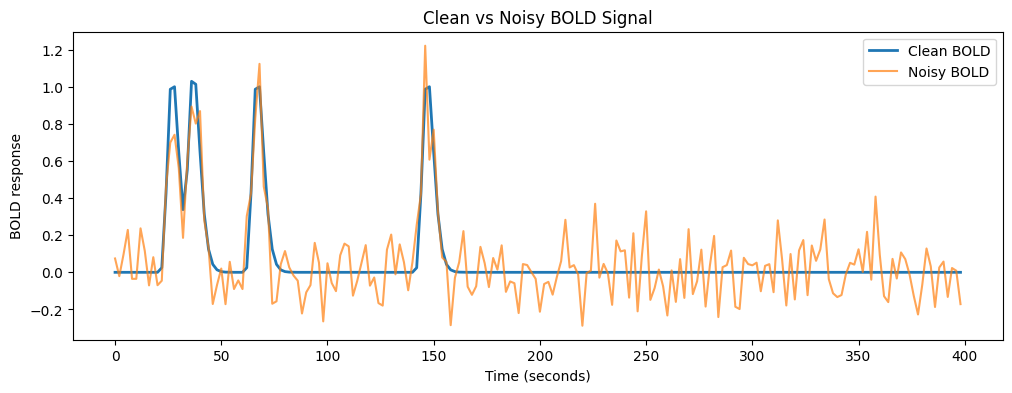

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Time configuration
TR = 2.0
n_points = 200

time = np.arange(n_points) * TR

# Simulated neural activity
neural_activity = np.zeros(n_points)

# Events at 20, 60, 100 and 140 seconds
event_times = [20,30,60,140]

for event_time in event_times:
    index = int(event_time / TR)
    neural_activity[index] = 1
# Visualize
plt.figure(figsize=(10, 3))
plt.stem(time, neural_activity)

plt.xlabel("Time (seconds)")
plt.ylabel("Neural event")
plt.title("Simulated Neural Activity")
plt.show()
# =============================================
# =============================================
from scipy.stats import gamma

hrf_time = np.arange(0, 30, TR)

hrf = gamma.pdf(hrf_time, a=8, scale=1)
hrf=hrf/hrf.max()         # this line just normalizes so that values between 0 and 1, if we dont do this, then we have values between 0 and 0.175 as max
                          # so we normalize it so we can look at it like a good boy

plt.figure(figsize=(10, 3))
plt.plot(hrf_time, hrf)

plt.xlabel("Time (seconds)")
plt.ylabel("Response strength")
plt.title("Hemodynamic Response Function")
plt.show()

# ==================================================
# ==================================================
# Apply the HRF to neural activity
bold_signal = np.convolve(neural_activity, hrf, mode="full")

# Keep the same number of time points as our experiment
bold_signal = bold_signal[:n_points]

# Plot the simulated BOLD signal
plt.figure(figsize=(10, 3))
plt.plot(time, bold_signal)

plt.xlabel("Time (seconds)")
plt.ylabel("BOLD response")
plt.title("Simulated BOLD Signal")
plt.show()

# ==========================================
# ==========================================

# Step 4: Add random noise to BOLD

np.random.seed(42)

noise = np.random.normal(
    loc=0,
    scale=0.15,
    size=n_points
)

noisy_bold = bold_signal + noise

plt.figure(figsize=(12, 4))

plt.plot(time, bold_signal, label="Clean BOLD", linewidth=2)
plt.plot(time, noisy_bold, label="Noisy BOLD", alpha=0.7)

plt.xlabel("Time (seconds)")
plt.ylabel("BOLD response")
plt.title("Clean vs Noisy BOLD Signal")
plt.legend()
plt.show()
